In [1]:

import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from numpy import genfromtxt
import os

path_to_csv = os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnet86Kparams_SGD_WD/logs/lightning_logs/version_0/metrics.csv')
# print(os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnet86Kparams_SGD_WD/logs/lightning_logs/version_0/metrics.csv'))
# Dataset
import pandas as pd
def plot_results(path):
    df=pd.read_csv(path, sep=',',header=[0])
    fig, axes = plt.subplots(nrows=2, ncols=2)
    x = 'epoch'
    print(df.columns)
    df.plot(x=x, y='train_loss', ax=axes[0,0])
    df.plot(x=x, y='train_acc', ax=axes[0,1], kind='line')
    df.plot(x=x, y='val_loss', ax=axes[1,0], kind='line')
    df.plot(x=x, y='val_acc', ax=axes[1,1], kind='line')

import yaml

def read_yaml(path):
    with open(path, 'r') as stream:
        try:
            parsed_yaml=yaml.safe_load(stream)
            return parsed_yaml
        except yaml.YAMLError as exc:
            print(exc)


## Baseline con Rete piccola
Portato risultati che non si avvicinano al 90 di accuracy nel validation set.
Utilizzato rete piccola sia con SGD che Adamw.
Lr = 0.005 con cosine decay.

Risultato migliore resnet_small_cifar10 con 0,88 di accuracy

## Resnet Standard + Img size 32
Risultati peggiori in assoluto, anche utilizzando il pretrain + sgd

## Img size 226 + resnet50 standard
Resize delle immagini da 32 a 225 
Trainato con AdamW lr=0.0005 
risultato migliore Rete pretrainata val_acc 0,95.
Molto strano il fatto che è perennemente intorno al 94/95
Rete non pretrainata val_acc 0,87

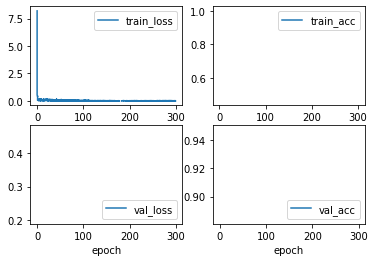

In [40]:
path_to_baseline_resnet50_SGD_PRETRAINED = os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/baseline_226imgSize_Pretrained/logs/lightning_logs/version_0/metrics.csv')
#hparams_baseline_resnet50_SGD_PRETRAINED = read_yaml(os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/baseline_resnet50_SGD_PRETRAINED/logs/lightning_logs/version_0/hparams.yaml'))
plot_results(path_to_baseline_resnet50_SGD_PRETRAINED)


## Resnet 86k parametri + SGD + Weight decay = 0,0001

Index(['train_loss', 'epoch', 'step', 'val_loss', 'val_acc'], dtype='object')


KeyError: 'train_acc'

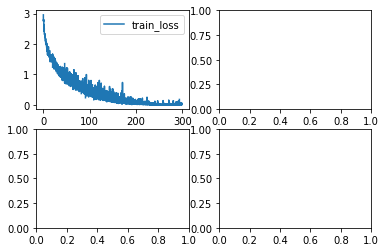

In [45]:
path_to_resnet86Kparams_SGD_WD = os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnet86Kparams_SGD_WD/logs/lightning_logs/version_0/metrics.csv')
hparams_resnet86Kparams_SGD_WD = read_yaml(os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnet86Kparams_SGD_WD/logs/lightning_logs/version_0/hparams.yaml'))
plot_results(path_to_resnet86Kparams_SGD_WD)
print(f"learning rate {hparams_resnet86Kparams_SGD_WD['args']['lr']}")
print(f"weight decay {hparams_resnet86Kparams_SGD_WD['args']['weight_decay']} ")

## Per il momento non sembrano portare miglioramenti esorbitanti

### Utilizzando IMG size 126 risulta una merda.....DA VEDERE SE è COLPA DEL LR TROPPO BASSSSOOO

could not determine a constructor for the tag 'tag:yaml.org,2002:python/object:argparse.Namespace'
  in "/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/baseline_226imgSize_SGD/logs/lightning_logs/version_1/hparams.yaml", line 1, column 7
Index(['lr-SGD', 'step', 'train_loss', 'epoch', 'val_loss', 'val_acc',
       'train_acc'],
      dtype='object')


<AxesSubplot:xlabel='epoch'>

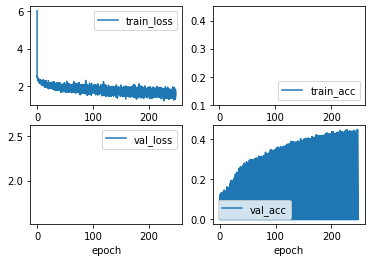

In [3]:
path= os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/baseline_226imgSize_SGD/logs/lightning_logs/version_1/metrics.csv')
hparams = read_yaml(os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/baseline_226imgSize_SGD/logs/lightning_logs/version_1/hparams.yaml'))

df=pd.read_csv(path, sep=',',header=[0])
fig, axes = plt.subplots(nrows=2, ncols=2)
x = 'epoch'
print(df.columns)
df['val_acc'] = df['val_acc'].fillna(0)
df.plot(x=x, y='train_loss', ax=axes[0,0])
df.plot(x=x, y='train_acc', ax=axes[0,1], kind='line')
df.plot(x=x, y='val_loss', ax=axes[1,0], kind='line')
df.plot(x=x, y='val_acc', ax=axes[1,1], kind='line')

## RISULTATI MIGLIORI CON RESNET OFFICIAL PER CIFAR 10  

could not determine a constructor for the tag 'tag:yaml.org,2002:python/object:argparse.Namespace'
  in "/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/logs/lightning_logs/version_1/hparams.yaml", line 1, column 7
Index(['lr-SGD', 'step', 'train_loss', 'epoch', 'val_loss', 'val_acc',
       'train_acc'],
      dtype='object')


<AxesSubplot:xlabel='epoch'>

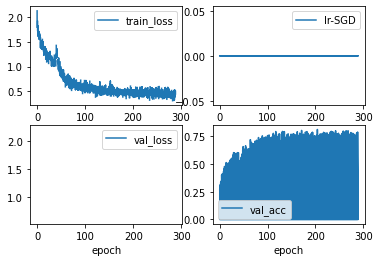

In [2]:
path= os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/logs/lightning_logs/version_1/metrics.csv')
hparams = read_yaml(os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/logs/lightning_logs/version_1/hparams.yaml'))

df=pd.read_csv(path, sep=',',header=[0])
fig, axes = plt.subplots(nrows=2, ncols=2)
x = 'epoch'
print(df.columns)
df['val_acc'] = df['val_acc'].fillna(0)
df['lr-SGD'] = df['lr-SGD'].fillna(0)

df.plot(x=x, y='train_loss', ax=axes[0,0])
df.plot(x=x, y='lr-SGD', ax=axes[0,1], kind='line')
df.plot(x=x, y='val_loss', ax=axes[1,0], kind='line')
df.plot(x=x, y='val_acc', ax=axes[1,1], kind='line')

In [3]:
path_baseline= os.path.join(sys.path[0], '/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/logs/lightning_logs/version_1/metrics.csv')
path_relResnet = os.path.join(sys.path[0],'/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD_REL/logs/lightning_logs/version_13/metrics.csv')
